
## Tahap 1. Pengenalan dan Pembacaan Dataset

### Tujuan

Tahap ini bertujuan untuk membaca dan mengenali struktur awal dataset *Power Consumption of Tetouan City* yang digunakan dalam proyek Smart City Multi-Zone Load Forecasting.

Dataset tersebut memuat informasi waktu pengukuran, kondisi lingkungan, dan konsumsi listrik pada tiga zona. Melalui tahap ini, kelompok dapat mengetahui jumlah observasi, jumlah variabel, nama kolom, serta contoh nilai yang tersedia sebelum dilakukan analisis dan pengolahan lebih lanjut.

### Proses yang Dilakukan

1. Mengimpor pustaka Python yang diperlukan untuk pengolahan data.
2. Mengunggah dataset berformat CSV ke Google Colab.
3. Membaca dataset menggunakan pustaka Pandas.
4. Merapikan penulisan nama kolom agar lebih konsisten.
5. Menampilkan dimensi dataset, daftar variabel, dan lima baris pertama.

### Hasil yang Diharapkan

Dataset berhasil dibaca dan ditampilkan dalam bentuk tabel sehingga struktur data serta variabel target dapat diidentifikasi sebagai dasar untuk tahap *Exploratory Data Analysis* (EDA) dan pemodelan RNN.


In [ ]:

# ==================================================
# TUGAS BESAR KECERDASAN BUATAN - KELOMPOK 7
# MINGGU 12: EDA, PREPROCESSING, BASELINE RNN
# ==================================================

# TAHAP 1: MEMBACA DAN MENGENALI DATASET

# Library untuk membaca dan mengolah dataset
import pandas as pd
import numpy as np

# Library untuk upload file dari komputer
from google.colab import files

# Library untuk menampilkan judul dan tabel
from IPython.display import display, Markdown

# 1. Menampilkan judul proyek
display(Markdown(
    "# Smart City Multi-Zone Load Forecasting\n"
    "### Kelompok 7 | Progres Minggu 12\n"
    "**Dataset: Power Consumption of Tetouan City "
    "(UCI ID 849)**"
))

# 2. Mengunggah dataset CSV
uploaded = files.upload()

# 3. Mengambil nama file yang diunggah
nama_file = next(iter(uploaded))

# 4. Membaca dataset menggunakan Pandas
df = pd.read_csv(nama_file)

# 5. Merapikan nama kolom
df.columns = (
    df.columns
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# 6. Menampilkan informasi dasar
display(Markdown("## Tahap 1. Pengenalan Dataset"))

print("Nama file:", nama_file)
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

print("\nDaftar kolom dataset:")
for nomor, kolom in enumerate(df.columns, start=1):
    print(f"{nomor}. {kolom}")

# 7. Menampilkan lima baris pertama
display(Markdown("### Lima Baris Pertama Dataset"))
display(df.head())

print("\nTAHAP 1 BERHASIL!")

# Smart City Multi-Zone Load Forecasting
### Kelompok 7 | Progres Minggu 12
**Dataset: Power Consumption of Tetouan City (UCI ID 849)**

Saving Tetuan City power consumption.csv to Tetuan City power consumption.csv


## Tahap 1. Pengenalan Dataset

Nama file: Tetuan City power consumption.csv
Jumlah baris: 52416
Jumlah kolom: 9

Daftar kolom dataset:
1. DateTime
2. Temperature
3. Humidity
4. Wind Speed
5. general diffuse flows
6. diffuse flows
7. Zone 1 Power Consumption
8. Zone 2 Power Consumption
9. Zone 3 Power Consumption


### Lima Baris Pertama Dataset

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964



TAHAP 1 BERHASIL!



### Interpretasi Hasil Tahap 1

Berdasarkan hasil pembacaan dataset, diperoleh 52.416 observasi dengan sembilan kolom. Dataset terdiri atas satu variabel waktu (*DateTime*), lima variabel kondisi lingkungan, dan tiga variabel konsumsi listrik.

Kelima variabel lingkungan meliputi *Temperature*, *Humidity*, *Wind Speed*, *general diffuse flows*, dan *diffuse flows*. Ketiga variabel konsumsi listrik meliputi Zone 1 Power Consumption, Zone 2 Power Consumption, dan Zone 3 Power Consumption.

Ketiga variabel konsumsi listrik tersebut ditetapkan sebagai target prediksi pada proyek ini. Dengan demikian, model RNN yang dikembangkan diarahkan untuk menghasilkan prediksi konsumsi listrik pada tiga zona secara bersamaan.

Hasil pembacaan menunjukkan bahwa dataset berhasil dimuat ke Google Colab. Namun, pada tahap ini kualitas data, keteraturan waktu, dan keberadaan nilai kosong belum diperiksa. Pemeriksaan tersebut akan dilakukan pada Tahap 2.


## Tahap 2. Pemeriksaan Kualitas Dataset (*Data Quality Checking*)

### Tujuan

Tahap ini bertujuan untuk memeriksa kualitas dan konsistensi dataset *Power Consumption of Tetouan City* sebelum digunakan dalam proses analisis eksploratif dan pemodelan *Recurrent Neural Network* (RNN). Pemeriksaan dilakukan untuk mengetahui keberadaan nilai kosong, duplikasi data, kesesuaian tipe data, serta keteraturan interval pencatatan konsumsi listrik.

Pemeriksaan ini menjadi penting karena proyek menggunakan pendekatan *time-series forecasting*, yaitu prediksi berdasarkan urutan data historis. Ketidakteraturan waktu, data yang hilang, maupun kesalahan pembacaan tanggal berpotensi memengaruhi pembentukan *sequence* dan hasil evaluasi model.

### Proses yang Dilakukan

1. Memeriksa tipe data pada setiap kolom.
2. Mengonversi kolom DateTime menjadi tipe tanggal dan waktu.
3. Mengurutkan dataset secara kronologis.
4. Memeriksa jumlah *missing values* pada setiap variabel.
5. Mengidentifikasi duplikasi baris dan waktu pencatatan.
6. Memeriksa tanggal awal dan akhir pengamatan.
7. Memeriksa konsistensi interval pencatatan data.
8. Menampilkan ringkasan hasil pemeriksaan kualitas dataset.

### Hasil yang Diharapkan

Tahap ini menghasilkan informasi mengenai kelengkapan, keunikan, dan keteraturan waktu dataset. Hasil pemeriksaan digunakan untuk menentukan apakah data memerlukan pembersihan tambahan sebelum memasuki tahap *Exploratory Data Analysis* (EDA).

In [ ]:

# ==================================================
# TAHAP 2: PEMERIKSAAN KUALITAS DATASET
# ==================================================

import pandas as pd
from IPython.display import display, Markdown

# 1. Mengubah kolom DateTime menjadi tipe datetime
# Dataset menggunakan format bulan/hari/tahun
if not pd.api.types.is_datetime64_any_dtype(df["DateTime"]):
    df["DateTime"] = pd.to_datetime(
        df["DateTime"],
        format="%m/%d/%Y %H:%M"
    )

# 2. Mengurutkan dataset berdasarkan waktu
df = df.sort_values("DateTime").reset_index(drop=True)

display(Markdown(
    "## Tahap 2. Hasil Pemeriksaan Kualitas Dataset"
))

# ==================================================
# A. PEMERIKSAAN TIPE DATA
# ==================================================

display(Markdown("### 2.1 Pemeriksaan Tipe Data"))

tabel_tipe = pd.DataFrame({
    "Variabel": df.columns,
    "Tipe Data": df.dtypes.astype(str).values
})

display(tabel_tipe)

# ==================================================
# B. PEMERIKSAAN MISSING VALUES
# ==================================================

display(Markdown("### 2.2 Pemeriksaan Missing Values"))

tabel_missing = pd.DataFrame({
    "Variabel": df.columns,
    "Jumlah Missing": df.isnull().sum().values,
    "Persentase (%)": (
        df.isnull().mean().values * 100
    ).round(2)
})

display(tabel_missing)

# ==================================================
# C. PEMERIKSAAN DUPLIKASI
# ==================================================

display(Markdown("### 2.3 Pemeriksaan Duplikasi Data"))

duplikat_baris = int(df.duplicated().sum())
duplikat_waktu = int(
    df["DateTime"].duplicated().sum()
)

tabel_duplikat = pd.DataFrame({
    "Jenis Pemeriksaan": [
        "Duplikasi seluruh baris",
        "Duplikasi waktu pencatatan"
    ],
    "Jumlah": [
        duplikat_baris,
        duplikat_waktu
    ]
})

display(tabel_duplikat)

# ==================================================
# D. PEMERIKSAAN RENTANG DAN INTERVAL WAKTU
# ==================================================

display(Markdown("### 2.4 Pemeriksaan Waktu Pengamatan"))

# Menghitung selisih waktu antarbaris
interval = df["DateTime"].diff().dropna()

# Menghitung interval yang tidak sama dengan 10 menit
interval_tidak_sesuai = int(
    (interval != pd.Timedelta(minutes=10)).sum()
)

tabel_waktu = pd.DataFrame({
    "Komponen": [
        "Waktu pengamatan pertama",
        "Waktu pengamatan terakhir",
        "Interval pencatatan utama",
        "Jumlah interval tidak sesuai"
    ],
    "Hasil": [
        str(df["DateTime"].min()),
        str(df["DateTime"].max()),
        str(interval.mode().iloc[0]),
        interval_tidak_sesuai
    ]
})

display(tabel_waktu)

# ==================================================
# E. RINGKASAN KUALITAS DATASET
# ==================================================

display(Markdown("### 2.5 Ringkasan Data Quality"))

total_missing = int(df.isnull().sum().sum())

ringkasan_kualitas = pd.DataFrame({
    "Indikator": [
        "Jumlah observasi",
        "Jumlah variabel",
        "Total missing values",
        "Duplikasi baris",
        "Duplikasi waktu",
        "Interval tidak sesuai 10 menit"
    ],
    "Hasil": [
        len(df),
        len(df.columns),
        total_missing,
        duplikat_baris,
        duplikat_waktu,
        interval_tidak_sesuai
    ]
})

display(ringkasan_kualitas)

# Memastikan tidak ada masalah kualitas yang terdeteksi
if (
    total_missing == 0
    and duplikat_baris == 0
    and duplikat_waktu == 0
    and interval_tidak_sesuai == 0
):
    print("STATUS: DATASET LOLOS PEMERIKSAAN KUALITAS DASAR")
else:
    print("STATUS: DATASET MEMERLUKAN PEMERIKSAAN LANJUTAN")

print("\nTAHAP 2 SELESAI!")

## Tahap 2. Hasil Pemeriksaan Kualitas Dataset

### 2.1 Pemeriksaan Tipe Data

,Variabel,Tipe Data
0,DateTime,datetime64[ns]
1,Temperature,float64
2,Humidity,float64
3,Wind Speed,float64
4,general diffuse flows,float64
5,diffuse flows,float64
6,Zone 1 Power Consumption,float64
7,Zone 2 Power Consumption,float64
8,Zone 3 Power Consumption,float64


### 2.2 Pemeriksaan Missing Values

,Variabel,Jumlah Missing,Persentase (%)
0,DateTime,0,0.0
1,Temperature,0,0.0
2,Humidity,0,0.0
3,Wind Speed,0,0.0
4,general diffuse flows,0,0.0
5,diffuse flows,0,0.0
6,Zone 1 Power Consumption,0,0.0
7,Zone 2 Power Consumption,0,0.0
8,Zone 3 Power Consumption,0,0.0


### 2.3 Pemeriksaan Duplikasi Data

... (2 outputs left out)

,Komponen,Hasil
0,Waktu pengamatan pertama,2017-01-01 00:00:00
1,Waktu pengamatan terakhir,2017-12-30 23:50:00
2,Interval pencatatan utama,0 days 00:10:00
3,Jumlah interval tidak sesuai,0


### 2.5 Ringkasan Data Quality

,Indikator,Hasil
0,Jumlah observasi,52416
1,Jumlah variabel,9
2,Total missing values,0
3,Duplikasi baris,0
4,Duplikasi waktu,0
5,Interval tidak sesuai 10 menit,0


STATUS: DATASET LOLOS PEMERIKSAAN KUALITAS DASAR

TAHAP 2 SELESAI!



### Interpretasi Hasil Tahap 2

Berdasarkan hasil pemeriksaan kualitas data, dataset *Power Consumption of Tetouan City* terdiri atas 52.416 observasi dengan sembilan variabel. Kolom DateTime berhasil dikonversi menjadi tipe data tanggal dan waktu, sedangkan variabel kondisi lingkungan dan konsumsi listrik dapat digunakan sebagai data numerik dalam proses analisis selanjutnya.

Hasil pemeriksaan menunjukkan bahwa tidak ditemukan *missing values* pada seluruh variabel. Selain itu, pemeriksaan duplikasi menghasilkan nilai nol, baik untuk keseluruhan baris maupun waktu pencatatan. Kondisi tersebut menunjukkan bahwa setiap observasi memiliki waktu pengamatan yang unik tanpa adanya data kosong yang teridentifikasi.

Berdasarkan pemeriksaan waktu, dataset mencakup periode 1 Januari 2017 pukul 00.00 hingga 30 Desember 2017 pukul 23.50 dengan interval pencatatan yang konsisten setiap 10 menit. Keteraturan tersebut mendukung penggunaan pendekatan *time-series forecasting* karena model RNN memerlukan data historis yang tersusun berdasarkan urutan waktu.

Secara keseluruhan, dataset memenuhi pemeriksaan kualitas dasar dan tidak memerlukan penghapusan baris akibat nilai kosong atau duplikasi pada data asli. Meskipun demikian, pemeriksaan ini belum mencakup analisis nilai ekstrem, distribusi, maupun pola konsumsi listrik. Analisis tersebut akan dilakukan pada tahap EDA untuk memahami karakteristik konsumsi energi pada ketiga zona.


## Tahap 3. Exploratory Data Analysis (EDA)

### 3A. Analisis Statistik Deskriptif Konsumsi Listrik

#### Tujuan

Tahap ini bertujuan untuk memahami karakteristik dasar konsumsi listrik pada ketiga zona dalam dataset *Power Consumption of Tetouan City*. Analisis statistik deskriptif dilakukan untuk mengidentifikasi besarnya konsumsi listrik, kecenderungan nilai pusat, serta tingkat variasi data sebelum proses pemodelan menggunakan RNN.

Melalui analisis ini, perbedaan karakteristik konsumsi listrik antarzona dapat diamati secara kuantitatif. Informasi tersebut menjadi dasar dalam memahami pola data dan menentukan pendekatan evaluasi yang sesuai untuk prediksi konsumsi listrik multizona.

#### Proses yang Dilakukan

1. Menentukan tiga variabel konsumsi listrik sebagai target analisis.
2. Menghitung jumlah data, rata-rata, median, standar deviasi, nilai minimum, dan maksimum pada setiap zona.
3. Menampilkan hasil statistik deskriptif dalam bentuk tabel.
4. Membuat grafik batang untuk membandingkan rata-rata konsumsi listrik ketiga zona.

#### Hasil yang Diharapkan

Tahap ini menghasilkan tabel statistik deskriptif dan grafik perbandingan rata-rata konsumsi listrik pada Zona 1, Zona 2, dan Zona 3. Hasil tersebut digunakan untuk mengidentifikasi perbedaan karakteristik konsumsi antarzona sebelum dilakukan analisis distribusi dan pola temporal.

### 3A.1 Statistik Deskriptif Konsumsi Listrik

,Jumlah Data,Rata-rata,Median,Standar Deviasi,Minimum,Maksimum
Zona 1,52416.0,32344.97,32265.92,7130.56,13895.70,52204.40
Zona 2,52416.0,21042.51,20823.17,5201.47,8560.08,37408.86
Zona 3,52416.0,17835.41,16415.12,6622.17,5935.17,47598.33


### 3A.2 Perbandingan Rata-rata Konsumsi Listrik

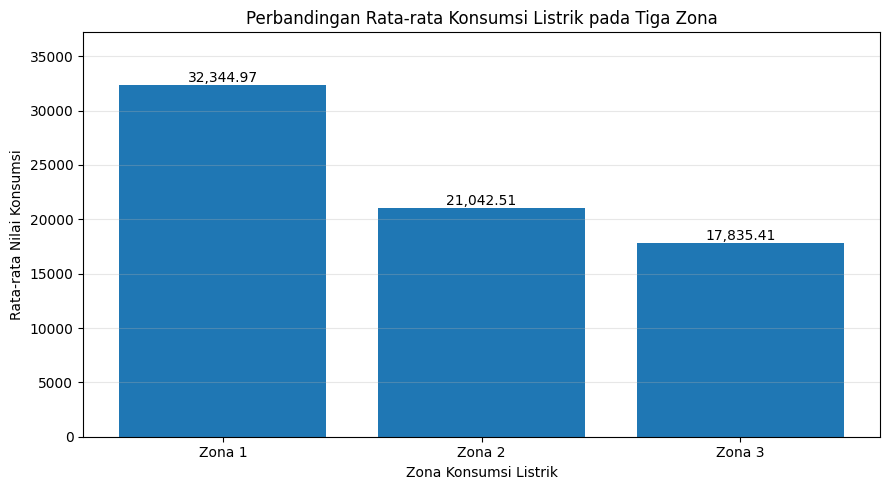

=== RINGKASAN STATISTIK ===
Rata-rata tertinggi: Zona 1
Rata-rata terendah: Zona 3

TAHAP 3A SELESAI!


In [ ]:

# ==================================================
# TAHAP 3A: ANALISIS STATISTIK DESKRIPTIF
# ==================================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 1. Menentukan target konsumsi listrik
zona = [
    "Zone 1 Power Consumption",
    "Zone 2 Power Consumption",
    "Zone 3 Power Consumption"
]

# 2. Menghitung statistik deskriptif
statistik_zona = df[zona].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
]).T

# 3. Merapikan nama kolom
statistik_zona.columns = [
    "Jumlah Data",
    "Rata-rata",
    "Median",
    "Standar Deviasi",
    "Minimum",
    "Maksimum"
]

# 4. Mengubah nama baris
statistik_zona.index = [
    "Zona 1",
    "Zona 2",
    "Zona 3"
]

# 5. Menampilkan tabel statistik
display(Markdown(
    "### 3A.1 Statistik Deskriptif Konsumsi Listrik"
))

display(statistik_zona.round(2))

# ==================================================
# 6. VISUALISASI RATA-RATA KONSUMSI
# ==================================================

display(Markdown(
    "### 3A.2 Perbandingan Rata-rata Konsumsi Listrik"
))

rata_rata = statistik_zona["Rata-rata"]

plt.figure(figsize=(9, 5))

batang = plt.bar(
    rata_rata.index,
    rata_rata.values
)

plt.title(
    "Perbandingan Rata-rata Konsumsi Listrik "
    "pada Tiga Zona"
)

plt.xlabel("Zona Konsumsi Listrik")
plt.ylabel("Rata-rata Nilai Konsumsi")

plt.grid(axis="y", alpha=0.3)

# Menampilkan nilai pada setiap batang
for bar in batang:

    tinggi = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        tinggi,
        f"{tinggi:,.2f}",
        ha="center",
        va="bottom"
    )

plt.ylim(
    0,
    rata_rata.max() * 1.15
)

plt.tight_layout()
plt.show()

# ==================================================
# 7. RINGKASAN HASIL
# ==================================================

zona_tertinggi = rata_rata.idxmax()
zona_terendah = rata_rata.idxmin()

print("=== RINGKASAN STATISTIK ===")

print(
    "Rata-rata tertinggi:",
    zona_tertinggi
)

print(
    "Rata-rata terendah:",
    zona_terendah
)

print("\nTAHAP 3A SELESAI!")

### Interpretasi Hasil Tahap 3A

Berdasarkan hasil statistik deskriptif, Zona 1 memiliki rata-rata konsumsi listrik tertinggi sebesar 32.344,97, diikuti Zona 2 sebesar 21.042,51 dan Zona 3 sebesar 17.835,41. Perbedaan tersebut menunjukkan bahwa setiap zona mempunyai karakteristik kebutuhan listrik yang tidak sama.

Zona 1 memiliki standar deviasi terbesar secara absolut, yaitu 7.130,56. Sementara itu, Zona 3 menunjukkan variasi yang relatif lebih besar terhadap rata-rata konsumsinya. Temuan ini menjadi dasar untuk menganalisis distribusi dan pola perubahan konsumsi listrik pada masing-masing zona sebelum pemodelan RNN.


### 3B. Analisis Distribusi Konsumsi Listrik

**Tujuan**

Tahap ini bertujuan untuk mengetahui pola persebaran konsumsi listrik pada ketiga zona menggunakan histogram dan *boxplot*. Analisis dilakukan untuk mengamati variasi data, kecenderungan distribusi, serta kemungkinan adanya nilai ekstrem.

**Proses**

1. Membuat histogram konsumsi listrik pada setiap zona.
2. Membuat *boxplot* untuk membandingkan sebaran ketiga zona.
3. Menghitung kemencengan distribusi (*skewness*) dan potensi nilai ekstrem menggunakan metode *Interquartile Range* (IQR).

**Hasil yang Diharapkan**

Diperoleh visualisasi dan ringkasan distribusi untuk memahami perbedaan karakteristik konsumsi listrik sebelum pemodelan RNN.

### 3B.1 Histogram Konsumsi Listrik

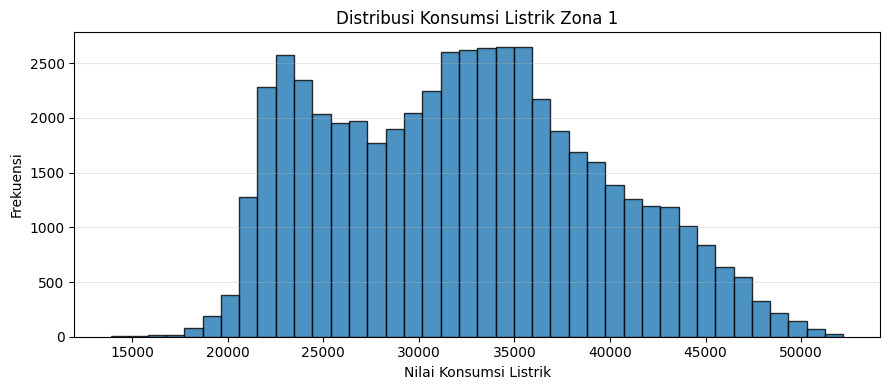

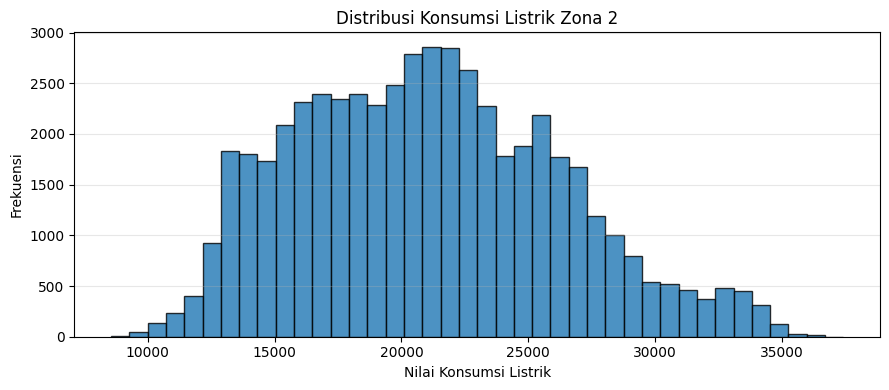

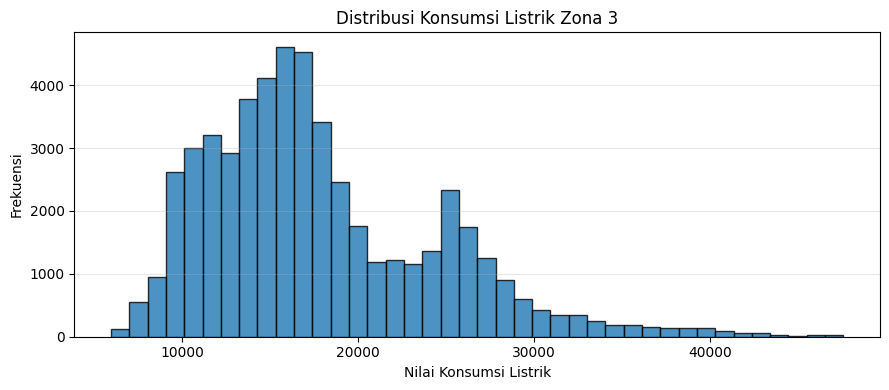

### 3B.2 Boxplot Konsumsi Listrik

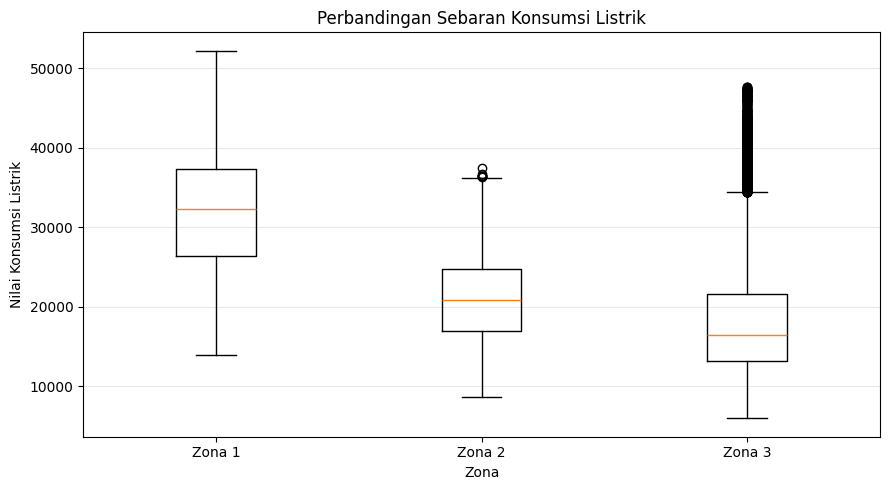

### 3B.3 Ringkasan Distribusi

,Zona,Skewness,IQR,Potensi Outlier
0,Zona 1,0.229,10998.349,0
1,Zona 2,0.329,7732.951,7
2,Zona 3,1.024,8494.774,1191



TAHAP 3B SELESAI!


In [ ]:

# ==================================================
# TAHAP 3B: ANALISIS DISTRIBUSI KONSUMSI LISTRIK
# ==================================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 1. Menggunakan tiga zona dari Tahap 3A
nama_zona = ["Zona 1", "Zona 2", "Zona 3"]

# 2. Membuat histogram untuk setiap zona
display(Markdown("### 3B.1 Histogram Konsumsi Listrik"))

for kolom, nama in zip(zona, nama_zona):

    plt.figure(figsize=(9, 4))

    plt.hist(
        df[kolom],
        bins=40,
        edgecolor="black",
        alpha=0.8
    )

    plt.title(f"Distribusi Konsumsi Listrik {nama}")
    plt.xlabel("Nilai Konsumsi Listrik")
    plt.ylabel("Frekuensi")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

# 3. Membuat boxplot ketiga zona
display(Markdown("### 3B.2 Boxplot Konsumsi Listrik"))

plt.figure(figsize=(9, 5))

plt.boxplot(
    [df[kolom].dropna() for kolom in zona],
    tick_labels=nama_zona,
    showfliers=True
)

plt.title("Perbandingan Sebaran Konsumsi Listrik")
plt.xlabel("Zona")
plt.ylabel("Nilai Konsumsi Listrik")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Menghitung ringkasan distribusi
hasil_distribusi = []

for kolom, nama in zip(zona, nama_zona):

    q1 = df[kolom].quantile(0.25)
    q3 = df[kolom].quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    outlier = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    hasil_distribusi.append({
        "Zona": nama,
        "Skewness": df[kolom].skew(),
        "IQR": iqr,
        "Potensi Outlier": int(outlier)
    })

# 5. Menampilkan ringkasan hasil
display(Markdown("### 3B.3 Ringkasan Distribusi"))

tabel_distribusi = pd.DataFrame(hasil_distribusi)

display(tabel_distribusi.round(3))

print("\nTAHAP 3B SELESAI!")


### Interpretasi Hasil Tahap 3B

Berdasarkan histogram dan boxplot, ketiga zona menunjukkan karakteristik distribusi konsumsi listrik yang berbeda. Zona 1 memiliki distribusi relatif lebih seimbang dengan nilai skewness sebesar 0,229, sedangkan Zona 2 menunjukkan kemencengan positif sebesar 0,329. Zona 3 memiliki kemencengan paling tinggi, yaitu 1,024, yang menunjukkan distribusi lebih condong ke kanan.

Berdasarkan metode Interquartile Range (IQR), tidak ditemukan outlier pada Zona 1, sedangkan Zona 2 memiliki 7 dan Zona 3 memiliki 1.191 potensi outlier. Nilai tersebut tidak langsung dihapus karena dapat mencerminkan variasi konsumsi listrik yang sebenarnya. Hasil ini menjadi dasar untuk menganalisis perubahan konsumsi berdasarkan waktu sebelum pemodelan RNN.


### 3C. Analisis Pola Konsumsi Listrik Berdasarkan Waktu

**Tujuan**

Tahap ini bertujuan untuk mengidentifikasi pola konsumsi listrik pada ketiga zona berdasarkan jam, hari, dan bulan. Analisis temporal dilakukan untuk mengetahui periode perubahan kebutuhan listrik serta pola berulang yang berpotensi dipelajari oleh model RNN.

**Proses**

1. Mengelompokkan konsumsi listrik berdasarkan jam (0–23).
2. Menghitung rata-rata konsumsi berdasarkan hari dalam seminggu.
3. Menganalisis perubahan rata-rata konsumsi setiap bulan.
4. Menampilkan grafik dan ringkasan waktu konsumsi tertinggi pada setiap zona.

**Hasil yang Diharapkan**

Diperoleh tiga grafik pola konsumsi listrik yang menggambarkan perubahan berdasarkan jam, hari, dan bulan sebagai dasar analisis karakteristik deret waktu.

### 3C.1 Pola Konsumsi Berdasarkan Jam

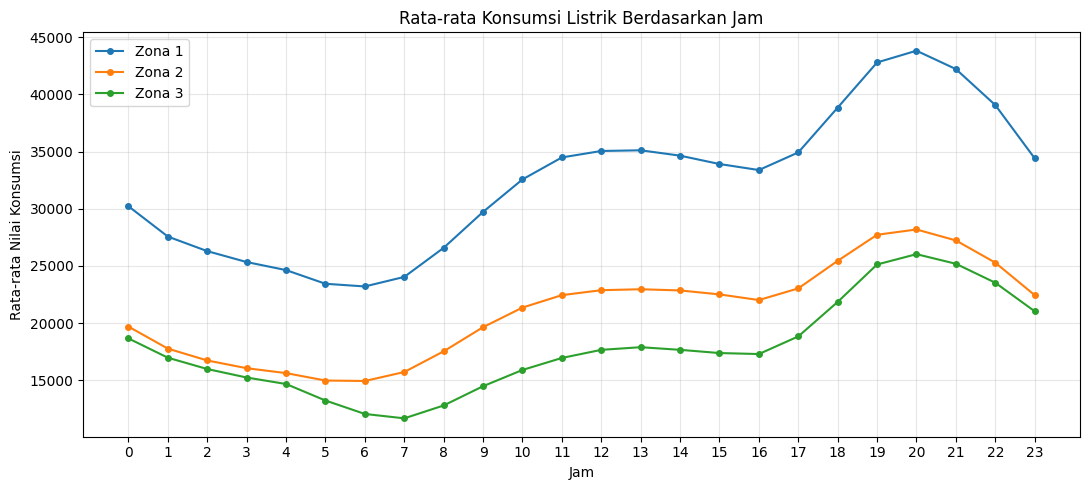

### 3C.2 Pola Konsumsi Berdasarkan Hari

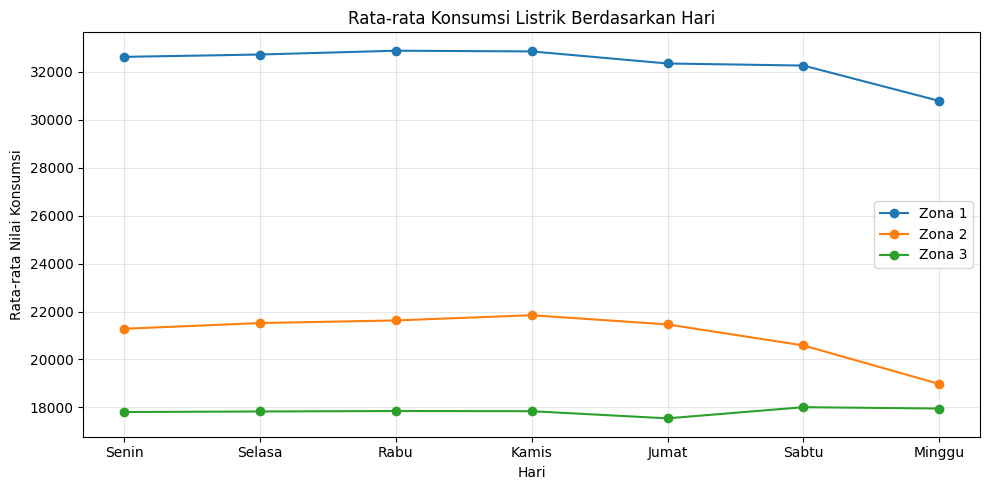

### 3C.3 Pola Konsumsi Berdasarkan Bulan

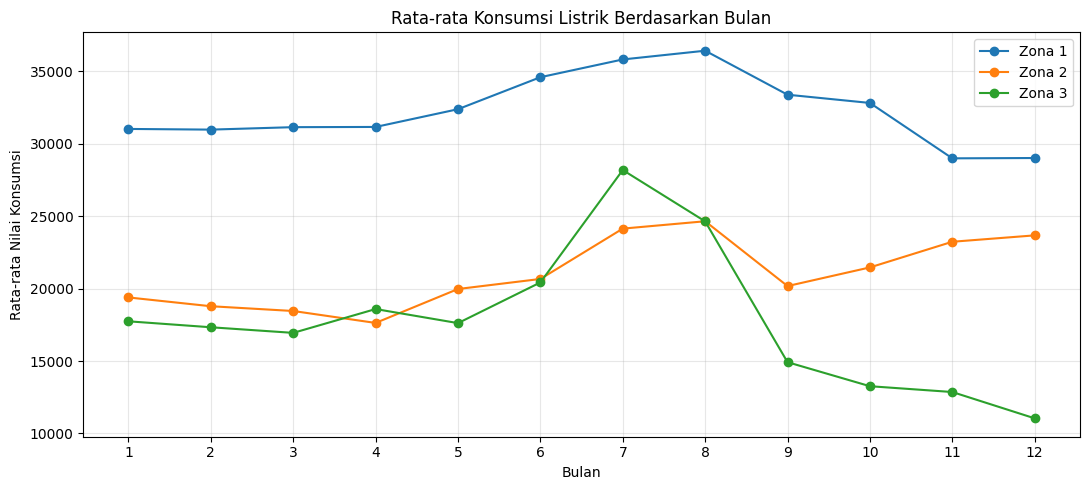

### 3C.4 Ringkasan Pola Temporal

,Zona,Jam Tertinggi,Hari Tertinggi,Bulan Tertinggi
0,Zona 1,20.00,Rabu,8
1,Zona 2,20.00,Kamis,8
2,Zona 3,20.00,Sabtu,7



TAHAP 3C SELESAI!


In [ ]:

# ==================================================
# TAHAP 3C: ANALISIS POLA KONSUMSI BERDASARKAN WAKTU
# ==================================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 1. Membuat variabel waktu
df["Hour"] = df["DateTime"].dt.hour
df["DayOfWeek"] = df["DateTime"].dt.dayofweek
df["Month"] = df["DateTime"].dt.month

nama_zona = ["Zona 1", "Zona 2", "Zona 3"]

# ==================================================
# A. POLA KONSUMSI BERDASARKAN JAM
# ==================================================

display(Markdown("### 3C.1 Pola Konsumsi Berdasarkan Jam"))

konsumsi_jam = df.groupby("Hour")[zona].mean()

plt.figure(figsize=(11, 5))

for kolom, nama in zip(zona, nama_zona):
    plt.plot(
        konsumsi_jam.index,
        konsumsi_jam[kolom],
        marker="o",
        markersize=4,
        label=nama
    )

plt.title("Rata-rata Konsumsi Listrik Berdasarkan Jam")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Nilai Konsumsi")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==================================================
# B. POLA KONSUMSI BERDASARKAN HARI
# ==================================================

display(Markdown("### 3C.2 Pola Konsumsi Berdasarkan Hari"))

konsumsi_hari = (
    df.groupby("DayOfWeek")[zona]
    .mean()
    .reindex(range(7))
)

nama_hari = [
    "Senin", "Selasa", "Rabu", "Kamis",
    "Jumat", "Sabtu", "Minggu"
]

plt.figure(figsize=(10, 5))

for kolom, nama in zip(zona, nama_zona):
    plt.plot(
        nama_hari,
        konsumsi_hari[kolom],
        marker="o",
        label=nama
    )

plt.title("Rata-rata Konsumsi Listrik Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Nilai Konsumsi")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==================================================
# C. POLA KONSUMSI BERDASARKAN BULAN
# ==================================================

display(Markdown("### 3C.3 Pola Konsumsi Berdasarkan Bulan"))

konsumsi_bulan = (
    df.groupby("Month")[zona]
    .mean()
    .reindex(range(1, 13))
)

plt.figure(figsize=(11, 5))

for kolom, nama in zip(zona, nama_zona):
    plt.plot(
        konsumsi_bulan.index,
        konsumsi_bulan[kolom],
        marker="o",
        label=nama
    )

plt.title("Rata-rata Konsumsi Listrik Berdasarkan Bulan")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata Nilai Konsumsi")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==================================================
# D. RINGKASAN POLA TEMPORAL
# ==================================================

display(Markdown("### 3C.4 Ringkasan Pola Temporal"))

ringkasan_temporal = []

for kolom, nama in zip(zona, nama_zona):

    jam_puncak = int(konsumsi_jam[kolom].idxmax())
    hari_puncak = int(konsumsi_hari[kolom].idxmax())
    bulan_puncak = int(konsumsi_bulan[kolom].idxmax())

    ringkasan_temporal.append({
        "Zona": nama,
        "Jam Tertinggi": f"{jam_puncak:02d}.00",
        "Hari Tertinggi": nama_hari[hari_puncak],
        "Bulan Tertinggi": bulan_puncak
    })

tabel_temporal = pd.DataFrame(ringkasan_temporal)

display(tabel_temporal)

print("\nTAHAP 3C SELESAI!")


### Interpretasi Hasil Tahap 3C

Berdasarkan analisis temporal, ketiga zona menunjukkan pola konsumsi listrik harian yang relatif serupa, dengan rata-rata konsumsi tertinggi terjadi pada pukul 20.00. Namun, terdapat perbedaan pola berdasarkan hari, yaitu Zona 1 tertinggi pada Rabu, Zona 2 pada Kamis, dan Zona 3 pada Sabtu.

Pada pola bulanan, Zona 1 dan Zona 2 mencapai rata-rata konsumsi tertinggi pada Agustus, sedangkan Zona 3 pada Juli. Perbedaan tersebut menunjukkan adanya variasi temporal antarzona, sehingga informasi waktu berpotensi menjadi fitur penting dalam pemodelan RNN.


### 3D. Analisis Korelasi Variabel

**Tujuan**

Tahap ini bertujuan untuk menganalisis hubungan antara variabel lingkungan dan konsumsi listrik pada ketiga zona menggunakan korelasi Pearson. Analisis dilakukan untuk mengetahui arah serta kekuatan hubungan linear antarvariabel.

**Proses**

1. Memilih lima variabel lingkungan dan tiga variabel konsumsi listrik.
2. Menghitung matriks korelasi Pearson.
3. Menampilkan *correlation heatmap*.
4. Mengidentifikasi korelasi setiap variabel lingkungan terhadap konsumsi listrik ketiga zona.

**Hasil yang Diharapkan**

Diperoleh matriks korelasi dan tabel hubungan variabel lingkungan terhadap konsumsi listrik sebagai informasi awal untuk memahami karakteristik data sebelum seleksi fitur menggunakan Genetic Algorithm (GA).

### 3D.1 Correlation Heatmap

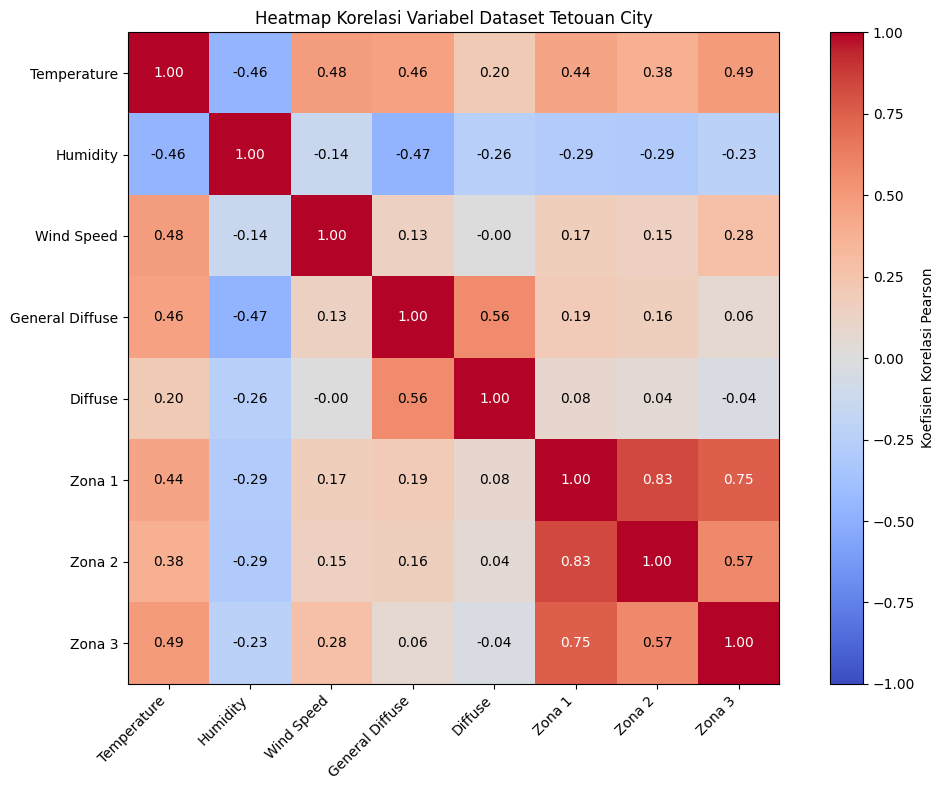

### 3D.2 Korelasi Lingkungan terhadap Konsumsi

,Zona 1,Zona 2,Zona 3
Temperature,0.440,0.382,0.490
Humidity,-0.287,-0.295,-0.233
Wind Speed,0.167,0.146,0.279
general diffuse flows,0.188,0.157,0.063
diffuse flows,0.080,0.045,-0.039


### 3D.3 Ringkasan Korelasi

Zona 1: Temperature (r = 0.440)
Zona 2: Temperature (r = 0.382)
Zona 3: Temperature (r = 0.490)

TAHAP 3D SELESAI!


In [ ]:

# ==================================================
# TAHAP 3D: ANALISIS KORELASI VARIABEL
# ==================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 1. Menentukan variabel lingkungan
fitur_lingkungan = [
    "Temperature",
    "Humidity",
    "Wind Speed",
    "general diffuse flows",
    "diffuse flows"
]

# 2. Menggabungkan variabel lingkungan dan target
kolom_korelasi = fitur_lingkungan + zona

# 3. Menghitung korelasi Pearson
matriks_korelasi = df[kolom_korelasi].corr(
    method="pearson"
)

# ==================================================
# A. HEATMAP KORELASI
# ==================================================

display(Markdown("### 3D.1 Correlation Heatmap"))

fig, ax = plt.subplots(figsize=(11, 8))

gambar = ax.imshow(
    matriks_korelasi,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Menampilkan nama variabel
nama_label = [
    "Temperature",
    "Humidity",
    "Wind Speed",
    "General Diffuse",
    "Diffuse",
    "Zona 1",
    "Zona 2",
    "Zona 3"
]

ax.set_xticks(range(len(nama_label)))
ax.set_yticks(range(len(nama_label)))

ax.set_xticklabels(nama_label, rotation=45, ha="right")
ax.set_yticklabels(nama_label)

# Menampilkan angka korelasi pada setiap sel
for i in range(len(nama_label)):
    for j in range(len(nama_label)):

        nilai = matriks_korelasi.iloc[i, j]

        ax.text(
            j, i,
            f"{nilai:.2f}",
            ha="center",
            va="center",
            color="white" if abs(nilai) > 0.6 else "black"
        )

plt.colorbar(
    gambar,
    ax=ax,
    label="Koefisien Korelasi Pearson"
)

plt.title("Heatmap Korelasi Variabel Dataset Tetouan City")
plt.tight_layout()
plt.show()

# ==================================================
# B. KORELASI LINGKUNGAN TERHADAP TARGET
# ==================================================

display(Markdown(
    "### 3D.2 Korelasi Lingkungan terhadap Konsumsi"
))

# Mengambil hanya hubungan lingkungan dengan target
korelasi_target = matriks_korelasi.loc[
    fitur_lingkungan, zona
].copy()

# Merapikan nama kolom
korelasi_target.columns = [
    "Zona 1",
    "Zona 2",
    "Zona 3"
]

display(korelasi_target.round(3))

# ==================================================
# C. RINGKASAN KORELASI
# ==================================================

display(Markdown("### 3D.3 Ringkasan Korelasi"))

for nama in korelasi_target.columns:

    fitur_terkuat = (
        korelasi_target[nama].abs().idxmax()
    )

    nilai = korelasi_target.loc[
        fitur_terkuat, nama
    ]

    print(
        f"{nama}: {fitur_terkuat} "
        f"(r = {nilai:.3f})"
    )

print("\nTAHAP 3D SELESAI!")


### Interpretasi Hasil Tahap 3D

Berdasarkan analisis korelasi Pearson, temperatur menunjukkan hubungan positif dengan konsumsi listrik pada ketiga zona, dengan nilai korelasi tertinggi pada Zona 3 sebesar 0,490. Sebaliknya, kelembapan menunjukkan korelasi negatif terhadap seluruh zona.

Korelasi antarzona juga menunjukkan hubungan positif, terutama antara Zona 1 dan Zona 2 sebesar 0,83. Hasil ini mengindikasikan adanya keterkaitan pola konsumsi listrik antarzona. Namun, korelasi belum menentukan fitur terbaik secara langsung karena seleksi fitur akan dilakukan menggunakan Genetic Algorithm (GA) pada tahap berikutnya.


## Tahap 4. Feature Engineering

### 4A. Pembentukan Fitur Waktu

**Tujuan**

Tahap ini bertujuan untuk membentuk fitur waktu dari kolom DateTime agar model RNN dapat mempelajari pola konsumsi listrik berdasarkan jam, hari, dan bulan.

**Proses**

1. Mengekstraksi informasi jam, hari, dan bulan.
2. Membentuk fitur Hour_sin dan Hour_cos untuk merepresentasikan pola waktu yang berulang setiap 24 jam.
3. Menampilkan hasil pembentukan fitur waktu.

**Hasil yang Diharapkan**

Diperoleh lima fitur waktu yang dapat digunakan untuk mendukung pemodelan konsumsi listrik berbasis RNN.

In [ ]:

# ==================================================
# TAHAP 4A: FEATURE ENGINEERING WAKTU
# ==================================================

import numpy as np
from IPython.display import display, Markdown

# 1. Mengambil informasi waktu dari DateTime
df["Hour"] = df["DateTime"].dt.hour
df["DayOfWeek"] = df["DateTime"].dt.dayofweek
df["Month"] = df["DateTime"].dt.month

# 2. Menghitung jam dalam bentuk desimal
# Contoh: 08:30 menjadi 8.5
jam_desimal = (
    df["DateTime"].dt.hour
    + df["DateTime"].dt.minute / 60
)

# 3. Membentuk fitur waktu siklik
df["Hour_sin"] = np.sin(
    2 * np.pi * jam_desimal / 24
)

df["Hour_cos"] = np.cos(
    2 * np.pi * jam_desimal / 24
)

# 4. Menentukan fitur waktu yang dibuat
fitur_waktu = [
    "Hour",
    "DayOfWeek",
    "Month",
    "Hour_sin",
    "Hour_cos"
]

# 5. Menampilkan hasil
display(Markdown(
    "### 4A.1 Hasil Pembentukan Fitur Waktu"
))

display(
    df[["DateTime"] + fitur_waktu].head(10)
)

# 6. Menampilkan jumlah data
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))

print("\nFitur waktu:")
for fitur in fitur_waktu:
    print("-", fitur)

print("\nTAHAP 4A SELESAI!")

### 4A.1 Hasil Pembentukan Fitur Waktu

,DateTime,Hour,DayOfWeek,Month,Hour_sin,Hour_cos
0,2017-01-01 00:00:00,0,6,1,0.000000,1.000000
1,2017-01-01 00:10:00,0,6,1,0.043619,0.999048
2,2017-01-01 00:20:00,0,6,1,0.087156,0.996195
3,2017-01-01 00:30:00,0,6,1,0.130526,0.991445
4,2017-01-01 00:40:00,0,6,1,0.173648,0.984808
5,2017-01-01 00:50:00,0,6,1,0.216440,0.976296
6,2017-01-01 01:00:00,1,6,1,0.258819,0.965926
7,2017-01-01 01:10:00,1,6,1,0.300706,0.953717
8,2017-01-01 01:20:00,1,6,1,0.342020,0.939693
9,2017-01-01 01:30:00,1,6,1,0.382683,0.923880


Jumlah baris: 52416
Jumlah kolom: 14

Fitur waktu:
- Hour
- DayOfWeek
- Month
- Hour_sin
- Hour_cos

TAHAP 4A SELESAI!



### Interpretasi Hasil Tahap 4A

Hasil feature engineering menunjukkan bahwa lima fitur waktu berhasil dibentuk, yaitu Hour, DayOfWeek, Month, Hour_sin, dan Hour_cos, sehingga jumlah kolom meningkat dari 9 menjadi 14 tanpa mengubah jumlah observasi.

Fitur Hour_sin dan Hour_cos merepresentasikan waktu secara siklik untuk membantu model RNN mengenali pola konsumsi listrik yang berulang setiap hari.



### 4B. Pembentukan Fitur Lag

**Tujuan**

Tahap ini bertujuan untuk membentuk fitur historis konsumsi listrik pada ketiga zona sebagai masukan tambahan bagi model RNN.

**Proses**

1. Membuat fitur lag 1 untuk merepresentasikan konsumsi listrik 10 menit sebelumnya.
2. Membuat fitur lag 144 untuk merepresentasikan konsumsi listrik 24 jam sebelumnya.
3. Memeriksa jumlah fitur dan nilai kosong yang terbentuk.

**Hasil yang Diharapkan**

Diperoleh enam fitur lag yang merepresentasikan riwayat konsumsi listrik pada ketiga zona.

In [ ]:

# ==================================================
# TAHAP 4B: FEATURE ENGINEERING LAG
# ==================================================

from IPython.display import display, Markdown

# 1. Menentukan variabel konsumsi listrik
zona = [
    "Zone 1 Power Consumption",
    "Zone 2 Power Consumption",
    "Zone 3 Power Consumption"
]

# 2. Membuat fitur lag pada ketiga zona
fitur_lag = []

for i, nama_kolom in enumerate(zona, start=1):

    # Konsumsi listrik 10 menit sebelumnya
    nama_lag_1 = f"Zone_{i}_Lag_1"
    df[nama_lag_1] = df[nama_kolom].shift(1)

    # Konsumsi listrik 24 jam sebelumnya
    nama_lag_144 = f"Zone_{i}_Lag_144"
    df[nama_lag_144] = df[nama_kolom].shift(144)

    fitur_lag.extend([
        nama_lag_1,
        nama_lag_144
    ])

# 3. Menampilkan daftar fitur lag
display(Markdown("### 4B.1 Fitur Lag yang Dibentuk"))

tabel_lag = pd.DataFrame({
    "Fitur": fitur_lag,
    "Jumlah Missing": df[fitur_lag].isnull().sum().values
})

display(tabel_lag)

# 4. Menampilkan contoh hasil
display(Markdown("### 4B.2 Contoh Hasil Fitur Lag"))

display(
    df[["DateTime", zona[0],
        "Zone_1_Lag_1",
        "Zone_1_Lag_144"]].iloc[144:149]
)

# 5. Menampilkan ukuran dataset
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("Jumlah fitur lag:", len(fitur_lag))

print("\nTAHAP 4B SELESAI!")

### 4B.1 Fitur Lag yang Dibentuk

,Fitur,Jumlah Missing
0,Zone_1_Lag_1,1
1,Zone_1_Lag_144,144
2,Zone_2_Lag_1,1
3,Zone_2_Lag_144,144
4,Zone_3_Lag_1,1
5,Zone_3_Lag_144,144


### 4B.2 Contoh Hasil Fitur Lag

,DateTime,Zone 1 Power Consumption,Zone_1_Lag_1,Zone_1_Lag_144
144,2017-01-02 00:00:00,26703.79747,27748.86076,34055.69620
145,2017-01-02 00:10:00,26169.11392,26703.79747,29814.68354
146,2017-01-02 00:20:00,25622.27848,26169.11392,29128.10127
147,2017-01-02 00:30:00,24972.15190,25622.27848,28228.86076
148,2017-01-02 00:40:00,24437.46835,24972.15190,27335.69620


Jumlah baris: 52416
Jumlah kolom: 20
Jumlah fitur lag: 6

TAHAP 4B SELESAI!



### Interpretasi Hasil Tahap 4B

Pembentukan fitur lag berhasil menghasilkan enam fitur historis konsumsi listrik sehingga jumlah kolom meningkat dari 14 menjadi 20. Fitur lag 1 merepresentasikan konsumsi 10 menit sebelumnya, sedangkan lag 144 menunjukkan konsumsi 24 jam sebelumnya.

Nilai kosong yang muncul merupakan konsekuensi dari tidak tersedianya riwayat pada awal pengamatan. Data tersebut akan ditangani sebelum pembagian dataset untuk pemodelan RNN.


## Tahap 5. Preprocessing Data untuk RNN

### 5A. Data Cleaning dan Data Splitting

**Tujuan**

Tahap ini bertujuan untuk menyiapkan dataset yang memiliki fitur historis lengkap dan membaginya menjadi data training, validation, dan testing secara kronologis.

**Proses**

1. Menghapus baris awal yang tidak memiliki nilai lag lengkap.
2. Membagi dataset dengan proporsi 70% training, 15% validation, dan 15% testing.
3. Memeriksa jumlah data serta rentang waktu setiap bagian.

**Hasil yang Diharapkan**

Diperoleh tiga bagian dataset yang tersusun berdasarkan waktu untuk mendukung pelatihan dan evaluasi RNN tanpa menggunakan data masa depan dalam proses pelatihan.


In [ ]:

# ==================================================
# TAHAP 5A: DATA CLEANING DAN DATA SPLITTING
# ==================================================

from IPython.display import display, Markdown

# 1. Menghapus baris tanpa riwayat lag lengkap
df_model = (
    df.dropna(subset=fitur_lag)
    .copy()
    .reset_index(drop=True)
)

# 2. Menghitung jumlah data
n_total = len(df_model)

# 3. Menentukan ukuran pembagian
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)

# 4. Membagi dataset berdasarkan urutan waktu
train_df = df_model.iloc[:n_train].copy()

val_df = df_model.iloc[
    n_train:n_train + n_val
].copy()

test_df = df_model.iloc[
    n_train + n_val:
].copy()

# 5. Membuat tabel ringkasan pembagian
ringkasan_split = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Jumlah Data": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "Waktu Awal": [
        train_df["DateTime"].min(),
        val_df["DateTime"].min(),
        test_df["DateTime"].min()
    ],
    "Waktu Akhir": [
        train_df["DateTime"].max(),
        val_df["DateTime"].max(),
        test_df["DateTime"].max()
    ]
})

# 6. Menampilkan hasil
display(Markdown(
    "### 5A.1 Ringkasan Pembagian Dataset"
))

display(ringkasan_split)

print("Data awal:", len(df))
print("Data setelah cleaning:", n_total)
print("Baris dihapus:", len(df) - n_total)

# 7. Memastikan pembagian tidak tumpang tindih
assert (
    len(train_df) + len(val_df) + len(test_df)
    == n_total
)

assert train_df["DateTime"].max() < val_df["DateTime"].min()
assert val_df["DateTime"].max() < test_df["DateTime"].min()

print("\nTAHAP 5A SELESAI!")

### 5A.1 Ringkasan Pembagian Dataset

,Dataset,Jumlah Data,Waktu Awal,Waktu Akhir
0,Training,36590,2017-01-02 00:00:00,2017-09-13 02:10:00
1,Validation,7840,2017-09-13 02:20:00,2017-11-06 12:50:00
2,Testing,7842,2017-11-06 13:00:00,2017-12-30 23:50:00


Data awal: 52416
Data setelah cleaning: 52272
Baris dihapus: 144

TAHAP 5A SELESAI!



### Interpretasi Hasil Tahap 5A

Setelah menghapus 144 baris awal yang belum memiliki riwayat lag lengkap, jumlah data berkurang dari 52.416 menjadi 52.272 observasi. Dataset kemudian dibagi secara kronologis menjadi 36.590 data training, 7.840 data validation, dan 7.842 data testing.

Pembagian berdasarkan urutan waktu dilakukan untuk menjaga proses evaluasi agar tidak menggunakan informasi dari periode masa depan saat pelatihan model RNN.



### 5B. Normalisasi Data

**Tujuan**

Tahap ini bertujuan untuk menyesuaikan skala fitur dan target menggunakan MinMaxScaler agar proses pelatihan RNN lebih stabil.

**Proses**

1. Menentukan fitur input dan target prediksi.
2. Melatih scaler hanya menggunakan data training.
3. Menerapkan normalisasi pada data training, validation, dan testing.
4. Memeriksa dimensi data setelah normalisasi.

**Hasil yang Diharapkan**

Diperoleh data numerik dengan 18 fitur input dan tiga target konsumsi listrik yang telah dinormalisasi tanpa menggunakan statistik dari data validation maupun testing.


In [ ]:

# ==================================================
# TAHAP 5B: NORMALISASI DATA
# ==================================================

from sklearn.preprocessing import MinMaxScaler

# 1. Menentukan fitur lingkungan
fitur_cuaca = [
    "Temperature",
    "Humidity",
    "Wind Speed",
    "general diffuse flows",
    "diffuse flows"
]

# 2. Menentukan fitur waktu untuk model
fitur_waktu_model = [
    "DayOfWeek",
    "Month",
    "Hour_sin",
    "Hour_cos"
]

# 3. Menggabungkan seluruh fitur input
feature_cols = (
    fitur_cuaca
    + fitur_waktu_model
    + zona
    + fitur_lag
)

# Target prediksi adalah konsumsi ketiga zona
target_cols = zona.copy()

# 4. Membuat dua scaler
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# 5. Fit hanya menggunakan data training
scaler_X.fit(train_df[feature_cols])
scaler_y.fit(train_df[target_cols])

# 6. Normalisasi fitur input
X_train = scaler_X.transform(
    train_df[feature_cols]
).astype(np.float32)

X_val = scaler_X.transform(
    val_df[feature_cols]
).astype(np.float32)

X_test = scaler_X.transform(
    test_df[feature_cols]
).astype(np.float32)

# 7. Normalisasi target
y_train = scaler_y.transform(
    train_df[target_cols]
).astype(np.float32)

y_val = scaler_y.transform(
    val_df[target_cols]
).astype(np.float32)

y_test = scaler_y.transform(
    test_df[target_cols]
).astype(np.float32)

# 8. Menyiapkan seluruh data untuk sequence RNN
# Scaler tetap menggunakan hasil fit dari training
X_all = scaler_X.transform(
    df_model[feature_cols]
).astype(np.float32)

y_all = scaler_y.transform(
    df_model[target_cols]
).astype(np.float32)

# 9. Menampilkan hasil normalisasi
display(Markdown(
    "### 5B.1 Hasil Normalisasi Data"
))

tabel_normalisasi = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Input (X)": [
        str(X_train.shape),
        str(X_val.shape),
        str(X_test.shape)
    ],
    "Target (y)": [
        str(y_train.shape),
        str(y_val.shape),
        str(y_test.shape)
    ]
})

display(tabel_normalisasi)

print("Jumlah fitur input:", len(feature_cols))
print("Jumlah target:", len(target_cols))

assert len(feature_cols) == 18
assert len(target_cols) == 3

print("\nTAHAP 5B SELESAI!")

### 5B.1 Hasil Normalisasi Data

,Dataset,Input (X),Target (y)
0,Training,"(36590, 18)","(36590, 3)"
1,Validation,"(7840, 18)","(7840, 3)"
2,Testing,"(7842, 18)","(7842, 3)"


Jumlah fitur input: 18
Jumlah target: 3

TAHAP 5B SELESAI!



### Interpretasi Hasil Tahap 5B

Normalisasi menggunakan MinMaxScaler berhasil diterapkan pada 18 fitur input dan tiga target konsumsi listrik. Dataset training terdiri atas 36.590 observasi, validation 7.840 observasi, dan testing 7.842 observasi.

Parameter normalisasi dihitung hanya dari data training untuk mencegah data leakage. Hasil normalisasi selanjutnya digunakan dalam pembentukan sequence sebagai masukan model RNN.



## Tahap 6. Pembentukan Sequence RNN

**Tujuan**

Tahap ini bertujuan untuk membentuk data historis berurutan sebagai masukan model Recurrent Neural Network (RNN).

**Proses**

1. Menetapkan panjang sequence sebesar 144 interval atau 24 jam.
2. Membentuk input dari 144 data sebelumnya untuk memprediksi konsumsi listrik 10 menit berikutnya.
3. Menyiapkan dataset training, validation, dan testing.
4. Membentuk DataLoader untuk proses pelatihan dan evaluasi.

**Hasil yang Diharapkan**

Diperoleh data input dengan bentuk 144 × 18 fitur dan target berupa tiga nilai konsumsi listrik untuk setiap sampel.


In [ ]:

# ==================================================
# TAHAP 6: PEMBENTUKAN SEQUENCE RNN
# ==================================================

import torch
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown

# 1. Menetapkan panjang riwayat
SEQ_LEN = 144

# 2. Membuat kelas dataset RNN
class DatasetRNN(Dataset):

    def __init__(self, X, y, start, end, seq_len):
        self.X = X
        self.y = y
        self.start = start
        self.end = end
        self.seq_len = seq_len

        assert start >= seq_len
        assert end <= len(X)
        assert len(X) == len(y)

    def __len__(self):
        return self.end - self.start

    def __getitem__(self, idx):

        # Posisi waktu yang akan diprediksi
        posisi = self.start + idx

        # Mengambil 144 interval SEBELUM target
        X_seq = self.X[
            posisi - self.seq_len:posisi
        ]

        # Konsumsi listrik pada waktu target
        y_target = self.y[posisi]

        return (
            torch.from_numpy(X_seq),
            torch.from_numpy(y_target)
        )

# 3. Dataset training
train_dataset = DatasetRNN(
    X_all, y_all,
    start=SEQ_LEN,
    end=n_train,
    seq_len=SEQ_LEN
)

# 4. Dataset validation
val_dataset = DatasetRNN(
    X_all, y_all,
    start=n_train,
    end=n_train + n_val,
    seq_len=SEQ_LEN
)

# 5. Dataset testing
test_dataset = DatasetRNN(
    X_all, y_all,
    start=n_train + n_val,
    end=len(X_all),
    seq_len=SEQ_LEN
)

# 6. Membentuk DataLoader
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# 7. Menampilkan jumlah sequence
display(Markdown("### 6.1 Hasil Pembentukan Sequence"))

tabel_sequence = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Jumlah Sequence": [
        len(train_dataset),
        len(val_dataset),
        len(test_dataset)
    ]
})

display(tabel_sequence)

# 8. Memeriksa dimensi input dan target
X_contoh, y_contoh = train_dataset[0]

print("Bentuk input RNN:", X_contoh.shape)
print("Bentuk target RNN:", y_contoh.shape)

# 9. Memeriksa ukuran batch
X_batch, y_batch = next(iter(train_loader))

print("\nBentuk batch input:", X_batch.shape)
print("Bentuk batch target:", y_batch.shape)

assert X_contoh.shape == (144, 18)
assert y_contoh.shape == (3,)

print("\nTAHAP 6 SELESAI!")

### 6.1 Hasil Pembentukan Sequence

,Dataset,Jumlah Sequence
0,Training,36446
1,Validation,7840
2,Testing,7842


Bentuk input RNN: torch.Size([144, 18])
Bentuk target RNN: torch.Size([3])

Bentuk batch input: torch.Size([64, 144, 18])
Bentuk batch target: torch.Size([64, 3])

TAHAP 6 SELESAI!



### Interpretasi Hasil Tahap 6

Pembentukan sequence RNN menghasilkan 36.446 sampel training, 7.840 sampel validation, dan 7.842 sampel testing. Setiap sampel memiliki 144 interval historis dengan 18 fitur input untuk memprediksi konsumsi listrik pada tiga zona dalam interval 10 menit berikutnya.

Hasil ini menunjukkan bahwa dataset berhasil disiapkan dalam format tiga dimensi yang sesuai untuk pelatihan model RNN.



## Tahap 7. Implementasi Baseline RNN

### 7A. Perancangan Arsitektur RNN

**Tujuan**

Tahap ini bertujuan untuk membangun arsitektur Baseline Recurrent Neural Network (RNN) sebagai model awal prediksi konsumsi listrik pada tiga zona.

**Proses**

1. Menentukan konfigurasi input, hidden layer, dan output.
2. Membangun Simple RNN dengan 64 hidden units.
3. Menambahkan fully connected layer untuk menghasilkan tiga nilai prediksi.
4. Memeriksa kesesuaian dimensi output model.

**Hasil yang Diharapkan**

Diperoleh arsitektur RNN yang dapat menerima 144 interval historis dengan 18 fitur dan menghasilkan prediksi konsumsi listrik untuk Zona 1, Zona 2, dan Zona 3.


In [ ]:

# ==================================================
# TAHAP 7A: MEMBANGUN ARSITEKTUR BASELINE RNN
# ==================================================

import torch
import torch.nn as nn
from IPython.display import display, Markdown

# 1. Menentukan seed agar hasil lebih konsisten
torch.manual_seed(42)

# 2. Menentukan perangkat komputasi
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 3. Membuat arsitektur Simple RNN
class BaselineRNN(nn.Module):

    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()

        # Layer RNN untuk mempelajari pola historis
        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        # Layer output untuk prediksi tiga zona
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):

        # Memproses seluruh sequence
        output, hidden = self.rnn(x)

        # Mengambil hasil pada interval terakhir
        output_terakhir = output[:, -1, :]

        # Menghasilkan prediksi tiga zona
        prediksi = self.fc(output_terakhir)

        return prediksi

# 4. Menentukan konfigurasi model
INPUT_SIZE = len(feature_cols)
HIDDEN_SIZE = 64
OUTPUT_SIZE = len(target_cols)

# 5. Membuat model RNN
model = BaselineRNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    output_size=OUTPUT_SIZE
).to(device)

# 6. Menguji bentuk keluaran model
X_batch, y_batch = next(iter(train_loader))

model.eval()

with torch.no_grad():
    prediksi = model(X_batch.to(device))

# 7. Menampilkan arsitektur dan hasil
display(Markdown("### 7A.1 Arsitektur Baseline RNN"))

print(model)

print("\nPerangkat:", device)
print("Input size:", INPUT_SIZE)
print("Hidden size:", HIDDEN_SIZE)
print("Output size:", OUTPUT_SIZE)

print("\nBentuk input:", X_batch.shape)
print("Bentuk prediksi:", prediksi.shape)
print("Bentuk target:", y_batch.shape)

# Menghitung jumlah parameter model
jumlah_parameter = sum(
    p.numel() for p in model.parameters()
)

print("\nJumlah parameter model:", jumlah_parameter)

assert prediksi.shape == y_batch.shape

print("\nTAHAP 7A SELESAI!")

### 7A.1 Arsitektur Baseline RNN

BaselineRNN(
  (rnn): RNN(18, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)

Perangkat: cpu
Input size: 18
Hidden size: 64
Output size: 3

Bentuk input: torch.Size([64, 144, 18])
Bentuk prediksi: torch.Size([64, 3])
Bentuk target: torch.Size([64, 3])

Jumlah parameter model: 5571

TAHAP 7A SELESAI!



### Interpretasi Hasil Tahap 7A

Arsitektur Baseline RNN berhasil dibangun menggunakan 18 fitur input, 64 hidden units, dan tiga neuron output. Model memiliki 5.571 parameter yang akan dipelajari selama pelatihan.

Dimensi prediksi sebesar (64, 3) telah sesuai dengan target, sehingga arsitektur siap digunakan untuk memprediksi konsumsi listrik ketiga zona.



### 7B. Pelatihan dan Validasi Baseline RNN

**Tujuan**

Tahap ini bertujuan untuk melatih model RNN menggunakan data historis konsumsi listrik serta mengevaluasi kemampuan model melalui data validation.

**Proses**

1. Menggunakan Mean Squared Error (MSE) sebagai fungsi loss.
2. Menggunakan optimizer Adam dengan learning rate 0,001.
3. Melatih RNN selama lima epoch.
4. Menghitung training loss dan validation loss.
5. Menampilkan grafik perkembangan loss dan mempertahankan model dengan validation loss terbaik.

**Hasil yang Diharapkan**

Diperoleh model RNN yang telah dilatih, tabel hasil setiap epoch, dan grafik training serta validation loss sebagai bahan evaluasi awal.


Epoch 1/5 | Train Loss: 0.003408 | Validation Loss: 0.000420
Epoch 2/5 | Train Loss: 0.000320 | Validation Loss: 0.000263
Epoch 3/5 | Train Loss: 0.000244 | Validation Loss: 0.000205
Epoch 4/5 | Train Loss: 0.000196 | Validation Loss: 0.000201
Epoch 5/5 | Train Loss: 0.000169 | Validation Loss: 0.000155


### 7B.1 Hasil Pelatihan RNN

,Epoch,Training Loss,Validation Loss
0,1,0.003408,0.000420
1,2,0.000320,0.000263
2,3,0.000244,0.000205
3,4,0.000196,0.000201
4,5,0.000169,0.000155


### 7B.2 Grafik Training dan Validation Loss

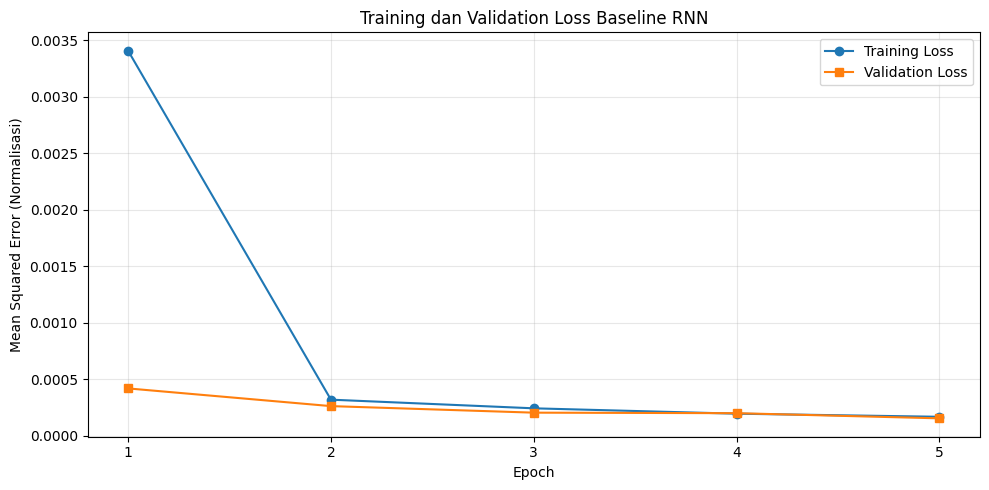

Epoch terbaik: 5
Validation loss terbaik: 0.000155

TAHAP 7B SELESAI!


In [ ]:

# ==================================================
# TAHAP 7B: PELATIHAN BASELINE RNN
# ==================================================

import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt
import copy
from IPython.display import display, Markdown

# 1. Menentukan fungsi loss dan optimizer
criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# 2. Menentukan jumlah epoch
EPOCHS = 5

# 3. Menyiapkan penyimpanan hasil pelatihan
riwayat_train = []
riwayat_val = []

best_val_loss = float("inf")
best_epoch = 0
best_state = None

# 4. Melatih model RNN
for epoch in range(EPOCHS):

    model.train()
    total_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Menghitung prediksi dan loss
        optimizer.zero_grad()
        prediksi = model(X_batch)
        loss = criterion(prediksi, y_batch)

        # Memperbarui bobot model
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_train_loss += (
            loss.item() * X_batch.size(0)
        )

    train_loss = total_train_loss / len(train_dataset)

    # 5. Menghitung validation loss
    model.eval()
    total_val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            prediksi = model(X_batch)
            loss = criterion(prediksi, y_batch)

            total_val_loss += (
                loss.item() * X_batch.size(0)
            )

    val_loss = total_val_loss / len(val_dataset)

    # 6. Mencatat riwayat loss
    riwayat_train.append(train_loss)
    riwayat_val.append(val_loss)

    # 7. Menyimpan bobot model terbaik di memori
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Validation Loss: {val_loss:.6f}",
        flush=True
    )

# 8. Menggunakan model dengan validation loss terbaik
model.load_state_dict(best_state)
model.eval()

# 9. Membuat tabel hasil pelatihan
display(Markdown("### 7B.1 Hasil Pelatihan RNN"))

tabel_training = pd.DataFrame({
    "Epoch": range(1, EPOCHS + 1),
    "Training Loss": riwayat_train,
    "Validation Loss": riwayat_val
})

display(tabel_training.round(6))

# 10. Membuat grafik training dan validation loss
display(Markdown("### 7B.2 Grafik Training dan Validation Loss"))

plt.figure(figsize=(10, 5))

plt.plot(
    tabel_training["Epoch"],
    tabel_training["Training Loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    tabel_training["Epoch"],
    tabel_training["Validation Loss"],
    marker="s",
    label="Validation Loss"
)

plt.title("Training dan Validation Loss Baseline RNN")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (Normalisasi)")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 11. Menampilkan hasil terbaik
print("Epoch terbaik:", best_epoch)
print(f"Validation loss terbaik: {best_val_loss:.6f}")

print("\nTAHAP 7B SELESAI!")


### Interpretasi Hasil Tahap 7B

Pelatihan Baseline RNN selama lima epoch menunjukkan penurunan training loss dari 0,003408 menjadi 0,000169, sedangkan validation loss menurun dari 0,000420 menjadi 0,000155. Hal ini menunjukkan bahwa model semakin mampu mempelajari pola konsumsi listrik selama proses pelatihan.

Epoch ke-5 menghasilkan validation loss terendah sehingga dipilih sebagai model terbaik sementara. Evaluasi selanjutnya dilakukan menggunakan data testing untuk mengukur performa prediksi pada ketiga zona.



## Tahap 8. Evaluasi dan Visualisasi Baseline RNN

### 8A. Evaluasi Menggunakan Data Testing

**Tujuan**

Tahap ini bertujuan untuk mengukur kemampuan Baseline RNN dalam memprediksi konsumsi listrik ketiga zona menggunakan data testing yang tidak digunakan selama pelatihan dan pemilihan model.

**Proses**

1. Menghasilkan prediksi dari data testing.
2. Mengembalikan nilai prediksi dan target ke skala aslinya.
3. Menghitung MAE, RMSE, dan R² untuk setiap zona.
4. Menampilkan hasil evaluasi dalam bentuk tabel.

**Hasil yang Diharapkan**

Diperoleh nilai evaluasi Baseline RNN yang dapat digunakan sebagai acuan perbandingan dengan model GA+RNN, PSO+RNN, dan GA+PSO+RNN.


In [ ]:

# ==================================================
# TAHAP 8A: EVALUASI BASELINE RNN
# ==================================================

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from IPython.display import display, Markdown

# 1. Menggunakan model terbaik dari Tahap 7B
model.eval()

# 2. Menyiapkan penampung prediksi dan target
semua_prediksi = []
semua_target = []

# 3. Melakukan prediksi pada data testing
with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        prediksi_batch = model(X_batch)

        semua_prediksi.append(
            prediksi_batch.cpu().numpy()
        )

        semua_target.append(
            y_batch.numpy()
        )

# 4. Menggabungkan hasil prediksi
y_pred_scaled = np.concatenate(
    semua_prediksi, axis=0
)

y_true_scaled = np.concatenate(
    semua_target, axis=0
)

# 5. Mengembalikan ke skala konsumsi asli
y_pred = scaler_y.inverse_transform(
    y_pred_scaled
)

y_true = scaler_y.inverse_transform(
    y_true_scaled
)

# 6. Menghitung metrik setiap zona
hasil_metrik = []

for i, nama in enumerate(["Zona 1", "Zona 2", "Zona 3"]):

    mae = mean_absolute_error(
        y_true[:, i], y_pred[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true[:, i], y_pred[:, i]
        )
    )

    r2 = r2_score(
        y_true[:, i], y_pred[:, i]
    )

    hasil_metrik.append({
        "Zona": nama,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# 7. Membuat tabel evaluasi
tabel_metrik = pd.DataFrame(hasil_metrik)

rata_rata = pd.DataFrame([{
    "Zona": "Rata-rata",
    "MAE": tabel_metrik["MAE"].mean(),
    "RMSE": tabel_metrik["RMSE"].mean(),
    "R2": tabel_metrik["R2"].mean()
}])

tabel_evaluasi = pd.concat(
    [tabel_metrik, rata_rata],
    ignore_index=True
)

# 8. Menampilkan hasil
display(Markdown(
    "### 8A.1 Hasil Evaluasi Baseline RNN"
))

display(tabel_evaluasi.round(4))

print("Jumlah sampel testing:", len(y_true))

assert len(y_true) == len(test_dataset)
assert y_pred.shape == y_true.shape

print("\nTAHAP 8A SELESAI!")

### 8A.1 Hasil Evaluasi Baseline RNN

,Zona,MAE,RMSE,R2
0,Zona 1,680.2307,792.9830,0.9829
1,Zona 2,256.4433,383.3762,0.9953
2,Zona 3,398.7462,557.9285,0.9725
3,Rata-rata,445.1401,578.0959,0.9836


Jumlah sampel testing: 7842

TAHAP 8A SELESAI!



### Interpretasi Hasil Tahap 8A

Evaluasi Baseline RNN menggunakan 7.842 sampel testing menghasilkan rata-rata MAE sebesar 445,1401, RMSE sebesar 578,0959, dan R² sebesar 0,9836. Nilai R² tertinggi diperoleh Zona 2 sebesar 0,9953, sedangkan Zona 3 memiliki R² terendah sebesar 0,9725.

Hasil tersebut menunjukkan kemampuan prediksi awal yang baik pada periode pengujian. Metrik ini selanjutnya digunakan sebagai acuan perbandingan dengan model yang dioptimasi menggunakan GA dan PSO.



### 8B. Visualisasi Hasil Prediksi dan Kesalahan

**Tujuan**

Tahap ini bertujuan untuk membandingkan nilai konsumsi listrik aktual dengan hasil prediksi Baseline RNN serta menganalisis kesalahan prediksi terhadap waktu.

**Proses**

1. Mengambil 144 sampel pertama dari data testing atau setara dengan 24 jam.
2. Membuat grafik aktual dan prediksi pada ketiga zona.
3. Menghitung selisih antara nilai aktual dan prediksi.
4. Menampilkan grafik kesalahan prediksi berdasarkan waktu.

**Hasil yang Diharapkan**

Diperoleh grafik aktual versus prediksi dan grafik kesalahan terhadap waktu untuk ketiga zona sebagai pelengkap evaluasi Baseline RNN.


### 8B.1 Visualisasi Zona 1

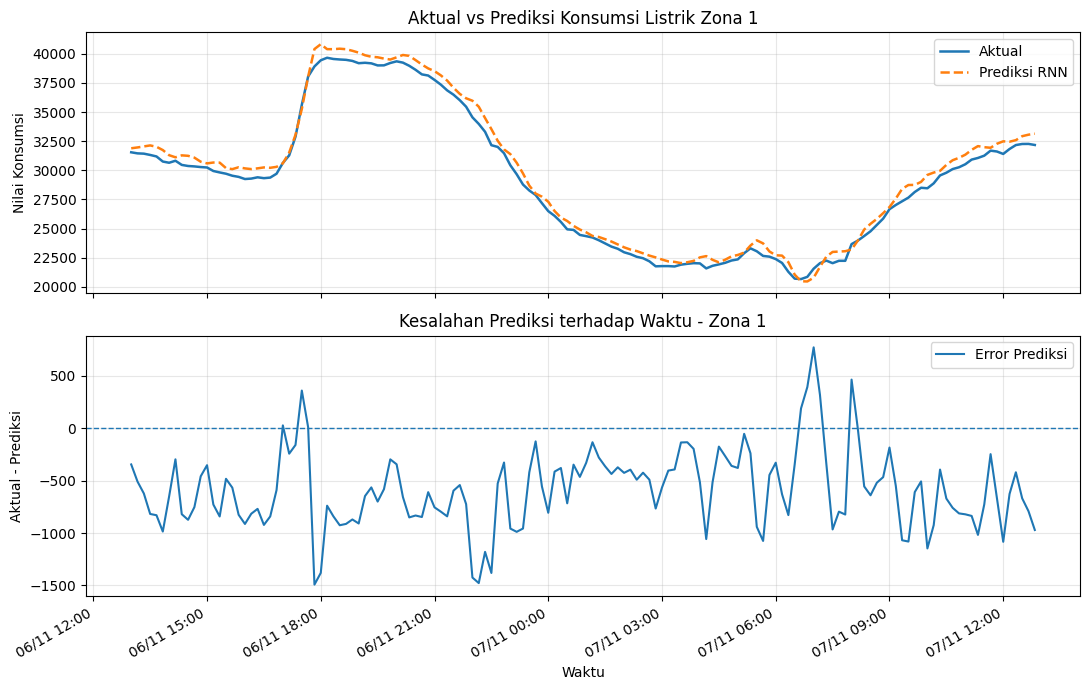

### 8B.2 Visualisasi Zona 2

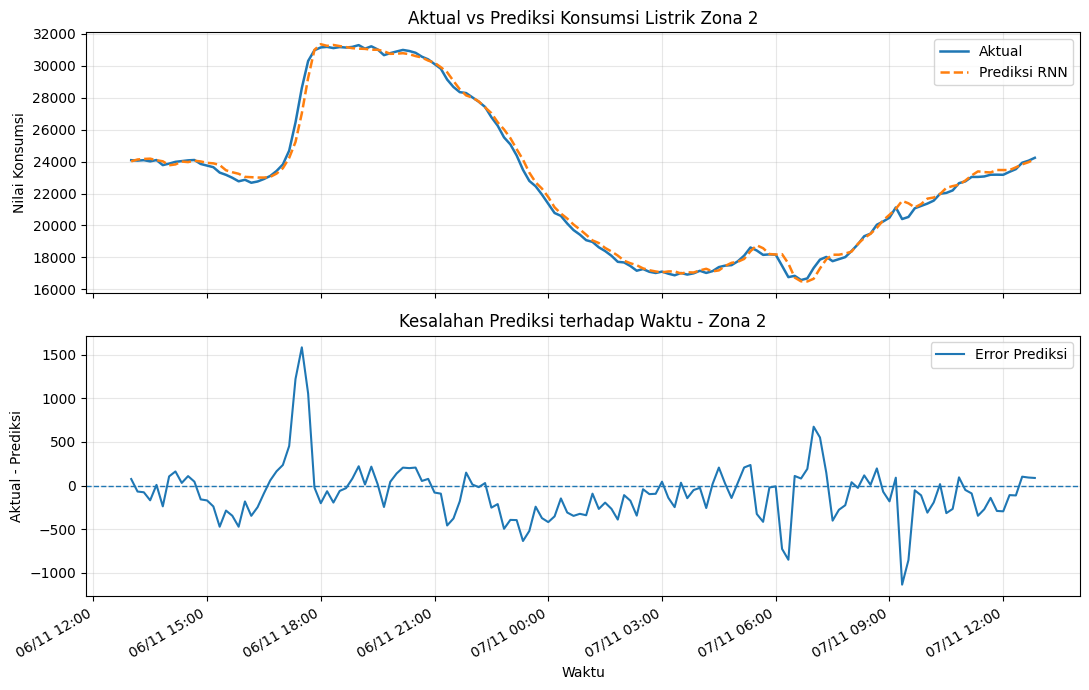

### 8B.3 Visualisasi Zona 3

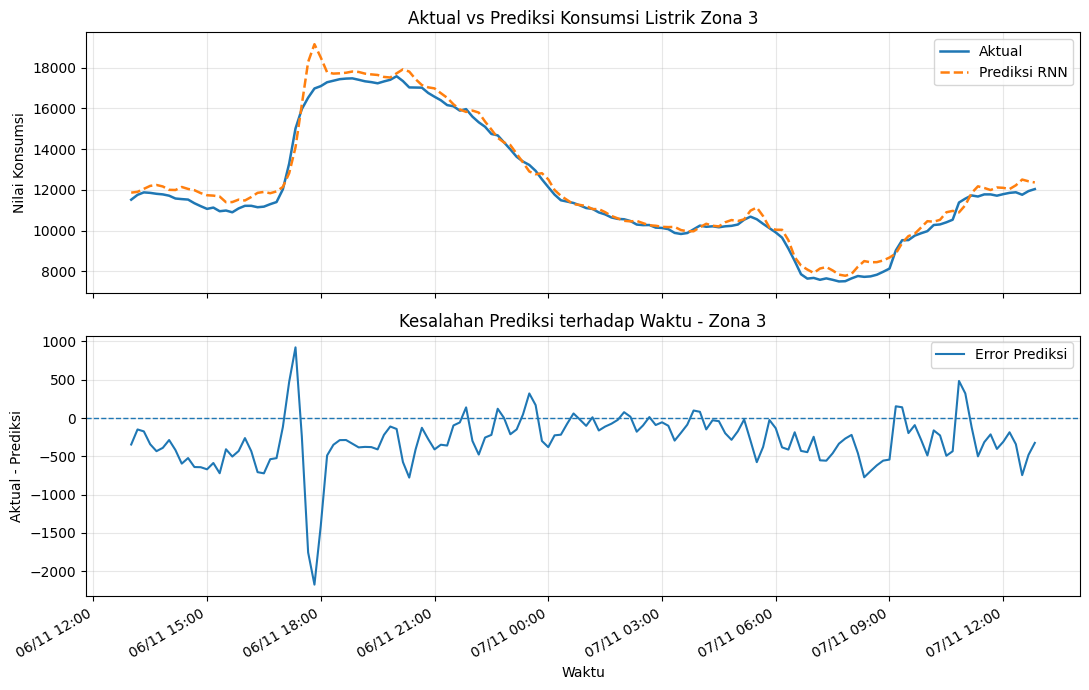

Jumlah sampel visualisasi: 144
Jumlah seluruh sampel testing: 7842

TAHAP 8B SELESAI!


In [ ]:

# ==================================================
# TAHAP 8B: VISUALISASI HASIL BASELINE RNN
# ==================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

# 1. Mengambil 144 sampel awal dari data testing
# 144 interval = 24 jam
N_PLOT = min(144, len(y_true))

waktu_plot = pd.to_datetime(
    test_df["DateTime"].iloc[:N_PLOT]
)

# 2. Menghitung kesalahan prediksi
# Error positif = aktual lebih besar dari prediksi
error_prediksi = y_true - y_pred

nama_zona = ["Zona 1", "Zona 2", "Zona 3"]

# 3. Menampilkan grafik setiap zona
for i, nama in enumerate(nama_zona):

    display(Markdown(
        f"### 8B.{i+1} Visualisasi {nama}"
    ))

    fig, axes = plt.subplots(
        2, 1,
        figsize=(11, 7),
        sharex=True
    )

    # Grafik aktual vs prediksi
    axes[0].plot(
        waktu_plot,
        y_true[:N_PLOT, i],
        label="Aktual",
        linewidth=1.8
    )

    axes[0].plot(
        waktu_plot,
        y_pred[:N_PLOT, i],
        label="Prediksi RNN",
        linestyle="--",
        linewidth=1.8
    )

    axes[0].set_title(
        f"Aktual vs Prediksi Konsumsi Listrik {nama}"
    )
    axes[0].set_ylabel("Nilai Konsumsi")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Grafik error terhadap waktu
    axes[1].plot(
        waktu_plot,
        error_prediksi[:N_PLOT, i],
        label="Error Prediksi"
    )

    axes[1].axhline(
        y=0,
        linestyle="--",
        linewidth=1
    )

    axes[1].set_title(
        f"Kesalahan Prediksi terhadap Waktu - {nama}"
    )
    axes[1].set_xlabel("Waktu")
    axes[1].set_ylabel("Aktual - Prediksi")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Merapikan label waktu
    axes[1].xaxis.set_major_formatter(
        mdates.DateFormatter("%d/%m %H:%M")
    )

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

# 4. Verifikasi jumlah sampel
assert len(test_df) == len(y_true)
assert y_pred.shape == y_true.shape

print("Jumlah sampel visualisasi:", N_PLOT)
print("Jumlah seluruh sampel testing:", len(y_true))
print("\nTAHAP 8B SELESAI!")


### Interpretasi Hasil Tahap 8B

Berdasarkan grafik aktual dan prediksi, Baseline RNN mampu mengikuti pola perubahan konsumsi listrik pada ketiga zona. Zona 2 menunjukkan kesesuaian prediksi yang relatif lebih baik, sedangkan Zona 1 dan Zona 3 masih memperlihatkan penyimpangan pada beberapa interval pengamatan.

Grafik kesalahan terhadap waktu menunjukkan bahwa kesalahan prediksi cenderung meningkat ketika terjadi perubahan konsumsi secara tajam. Temuan ini menunjukkan bahwa model telah mempelajari pola utama konsumsi listrik, tetapi masih memiliki keterbatasan dalam mengikuti perubahan mendadak.



## Tahap 9. Ringkasan dan Kesimpulan Baseline RNN

**Tujuan**

Tahap ini bertujuan untuk merangkum hasil pengolahan dataset, konfigurasi Baseline RNN, serta performa prediksi konsumsi listrik pada ketiga zona sebagai hasil akhir eksperimen awal Minggu 12.

**Proses**

1. Menampilkan ringkasan dataset dan preprocessing.
2. Menampilkan konfigurasi arsitektur serta pelatihan RNN.
3. Menyajikan kembali hasil evaluasi MAE, RMSE, dan R².
4. Memeriksa kelengkapan hasil dan menyusun kesimpulan awal.

**Hasil yang Diharapkan**

Diperoleh ringkasan eksperimen Baseline RNN yang dapat digunakan sebagai dokumentasi progres Minggu 12 dan acuan perbandingan dengan model GA+RNN, PSO+RNN, serta GA+PSO+RNN.


In [ ]:

# ==================================================
# TAHAP 9: RINGKASAN HASIL BASELINE RNN
# ==================================================

import pandas as pd
from IPython.display import display, Markdown

display(Markdown(
    "# RINGKASAN HASIL PROGRES MINGGU 12\n"
    "### Smart City Multi-Zone Load Forecasting\n"
    "**Kelompok 7 | Baseline RNN**"
))

# ==================================================
# A. RINGKASAN DATASET DAN PREPROCESSING
# ==================================================

display(Markdown("### 9.1 Ringkasan Dataset"))

ringkasan_data = pd.DataFrame({
    "Komponen": [
        "Dataset",
        "Jumlah data awal",
        "Jumlah data setelah preprocessing",
        "Jumlah fitur input",
        "Jumlah target",
        "Data training",
        "Data validation",
        "Data testing",
        "Training sequence",
        "Validation sequence",
        "Testing sequence",
        "Panjang sequence",
        "Horizon prediksi"
    ],
    "Hasil": [
        "Power Consumption of Tetouan City",
        len(df),
        len(df_model),
        len(feature_cols),
        len(target_cols),
        len(train_df),
        len(val_df),
        len(test_df),
        len(train_dataset),
        len(val_dataset),
        len(test_dataset),
        SEQ_LEN,
        "10 menit ke depan"
    ]
})

display(ringkasan_data)

# ==================================================
# B. KONFIGURASI BASELINE RNN
# ==================================================

display(Markdown("### 9.2 Konfigurasi Model RNN"))

ringkasan_model = pd.DataFrame({
    "Parameter": [
        "Arsitektur",
        "Input size",
        "Hidden units",
        "Output size",
        "Jumlah RNN layer",
        "Jumlah parameter model",
        "Batch size",
        "Learning rate",
        "Fungsi loss",
        "Optimizer",
        "Jumlah epoch",
        "Epoch terbaik",
        "Validation loss terbaik"
    ],
    "Nilai": [
        "Simple RNN",
        INPUT_SIZE,
        HIDDEN_SIZE,
        OUTPUT_SIZE,
        1,
        jumlah_parameter,
        BATCH_SIZE,
        0.001,
        "Mean Squared Error",
        "Adam",
        EPOCHS,
        best_epoch,
        f"{best_val_loss:.6f}"
    ]
})

display(ringkasan_model)

# ==================================================
# C. RINGKASAN EVALUASI MODEL
# ==================================================

display(Markdown("### 9.3 Hasil Evaluasi Model A"))

display(
    tabel_evaluasi.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}"
    })
)

# Mengambil rata-rata performa ketiga zona
rata_mae = tabel_evaluasi.iloc[-1]["MAE"]
rata_rmse = tabel_evaluasi.iloc[-1]["RMSE"]
rata_r2 = tabel_evaluasi.iloc[-1]["R2"]

print("Jumlah sampel testing:", len(y_true))
print(f"Rata-rata MAE  : {rata_mae:.4f}")
print(f"Rata-rata RMSE : {rata_rmse:.4f}")
print(f"Rata-rata R2   : {rata_r2:.4f}")

# ==================================================
# D. VERIFIKASI HASIL
# ==================================================

display(Markdown("### 9.4 Verifikasi Eksperimen"))

assert len(df) == 52416
assert len(df_model) == 52272
assert len(feature_cols) == 18
assert len(target_cols) == 3

assert len(train_dataset) == 36446
assert len(val_dataset) == 7840
assert len(test_dataset) == 7842

assert len(y_true) == 7842
assert y_pred.shape == y_true.shape
assert len(riwayat_train) == EPOCHS
assert len(riwayat_val) == EPOCHS

print("Dataset dan preprocessing: SESUAI")
print("Pembagian sequence: SESUAI")
print("Arsitektur RNN: SESUAI")
print("Riwayat training dan validation: TERSEDIA")
print("Evaluasi tiga zona: TERSEDIA")

# ==================================================
# E. KESIMPULAN OTOMATIS
# ==================================================

display(Markdown("### 9.5 Kesimpulan Awal"))

print(
    "Baseline RNN berhasil dilatih dan dievaluasi "
    "untuk prediksi konsumsi listrik tiga zona."
)

print(
    f"Model terbaik diperoleh pada epoch {best_epoch} "
    f"dengan validation loss {best_val_loss:.6f}."
)

print(
    f"Hasil testing menunjukkan rata-rata MAE "
    f"{rata_mae:.4f}, RMSE {rata_rmse:.4f}, "
    f"dan R2 {rata_r2:.4f}."
)

print(
    "Hasil Model A digunakan sebagai baseline "
    "untuk perbandingan eksperimen selanjutnya."
)

print("\nTAHAP 9 SELESAI!")
print("NOTEBOOK UTAMA MINGGU 12 SELESAI!")

# RINGKASAN HASIL PROGRES MINGGU 12
### Smart City Multi-Zone Load Forecasting
**Kelompok 7 | Baseline RNN**

### 9.1 Ringkasan Dataset

,Komponen,Hasil
0,Dataset,Power Consumption of Tetouan City
1,Jumlah data awal,52416
2,Jumlah data setelah preprocessing,52272
3,Jumlah fitur input,18
4,Jumlah target,3
5,Data training,36590
6,Data validation,7840
7,Data testing,7842
8,Training sequence,36446
9,Validation sequence,7840


### 9.2 Konfigurasi Model RNN

,Parameter,Nilai
0,Arsitektur,Simple RNN
1,Input size,18
2,Hidden units,64
3,Output size,3
4,Jumlah RNN layer,1
5,Jumlah parameter model,5571
6,Batch size,64
7,Learning rate,0.001
8,Fungsi loss,Mean Squared Error
9,Optimizer,Adam


### 9.3 Hasil Evaluasi Model A

... (2 outputs left out)

### 9.4 Verifikasi Eksperimen

Dataset dan preprocessing: SESUAI
Pembagian sequence: SESUAI
Arsitektur RNN: SESUAI
Riwayat training dan validation: TERSEDIA
Evaluasi tiga zona: TERSEDIA


### 9.5 Kesimpulan Awal

Baseline RNN berhasil dilatih dan dievaluasi untuk prediksi konsumsi listrik tiga zona.
Model terbaik diperoleh pada epoch 5 dengan validation loss 0.000155.
Hasil testing menunjukkan rata-rata MAE 445.1401, RMSE 578.0959, dan R2 0.9836.
Hasil Model A digunakan sebagai baseline untuk perbandingan eksperimen selanjutnya.

TAHAP 9 SELESAI!
NOTEBOOK UTAMA MINGGU 12 SELESAI!



### Kesimpulan Eksperimen Baseline RNN

Eksperimen Minggu 12 berhasil mengimplementasikan Baseline RNN untuk memprediksi konsumsi listrik pada tiga zona menggunakan dataset *Power Consumption of Tetouan City*. Model menggunakan 18 fitur input, 144 interval historis, dan tiga neuron output untuk memprediksi konsumsi listrik 10 menit berikutnya.

Hasil pengujian pada 7.842 sampel menunjukkan rata-rata MAE sebesar 445,1401, RMSE sebesar 578,0959, dan R² sebesar 0,9836. Hasil tersebut menunjukkan kemampuan prediksi awal yang baik, meskipun kesalahan masih terjadi pada beberapa perubahan konsumsi yang tajam.

Model ini ditetapkan sebagai baseline untuk mengevaluasi manfaat seleksi fitur menggunakan Genetic Algorithm (GA) dan optimasi hiperparameter menggunakan Particle Swarm Optimization (PSO) pada tahap eksperimen berikutnya.



### Penyimpanan Artefak Baseline RNN

Tahap ini bertujuan untuk menyimpan bobot Baseline RNN, parameter normalisasi, dan konfigurasi model yang telah dikembangkan pada Minggu 12. Artefak tersebut diperlukan agar model dapat digunakan kembali tanpa melakukan pelatihan ulang, khususnya pada tahap perbandingan model dan integrasi dashboard Streamlit.


In [17]:

# ==================================================
# PENYIMPANAN ARTEFAK BASELINE RNN MINGGU 12
# ==================================================

import torch
import joblib
import json
from pathlib import Path
from IPython.display import display, Markdown

# 1. Membuat folder penyimpanan di Colab
folder_model = Path("/content/W12_Model_A")
folder_model.mkdir(parents=True, exist_ok=True)

# 2. Menyimpan bobot RNN terbaik
torch.save(
    model.state_dict(),
    folder_model / "baseline_rnn.pth"
)

# 3. Menyimpan scaler input dan target
joblib.dump(
    scaler_X,
    folder_model / "scaler_X.pkl"
)

joblib.dump(
    scaler_y,
    folder_model / "scaler_y.pkl"
)

# 4. Menyimpan konfigurasi model
konfigurasi = {
    "model": "Baseline Simple RNN",
    "input_size": INPUT_SIZE,
    "hidden_size": HIDDEN_SIZE,
    "output_size": OUTPUT_SIZE,
    "sequence_length": SEQ_LEN,
    "feature_cols": feature_cols,
    "target_cols": target_cols,
    "best_epoch": best_epoch,
    "best_validation_loss": float(best_val_loss)
}

with open(
    folder_model / "konfigurasi.json", "w"
) as file:
    json.dump(konfigurasi, file, indent=4)

# 5. Memeriksa file yang tersimpan
display(Markdown("### Hasil Penyimpanan Model A"))

for file in sorted(folder_model.iterdir()):
    print(file.name, ":", file.is_file())

print("\nPENYIMPANAN ARTEFAK BERHASIL!")

### Hasil Penyimpanan Model A

baseline_rnn.pth : True
konfigurasi.json : True
scaler_X.pkl : True
scaler_y.pkl : True

PENYIMPANAN ARTEFAK BERHASIL!
